Materiais utilizados para produção do notebook: https://ia-labs.com.br/wp-content/uploads/2025/07/Segment-Anything-Models-SAMs-Modelos-de-Segmentacao-de-Qualquer-Coisa.pdf

In [9]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt

from domain.individuo_camarao import IndividuoCamarao
from segment_anything import sam_model_registry, SamPredictor
import torch
import os
import numpy as np


In [10]:
def listar_diretorio(path):
    return [
        os.path.join(path, path_image)
        for path_image in sorted(os.listdir(path))
    ]

In [11]:
from pathlib import Path

views_list_image_paths = []
labels_paths = []
for path in Path("../dataset_mvcnn/").iterdir():

    if path.is_dir():
        label = path.name
        
        for class_dir in path.iterdir():

            if class_dir.iterdir():
                views_list_image_paths.append(listar_diretorio(class_dir))
                labels_paths.append(label)

print(len(views_list_image_paths))
print(len(labels_paths))

199
199


Função que pega a pasta de cada indvíduo e retorna em um dicionário com as imagens das partes constituientes dos indivíduos

In [12]:
def read_image_individuo(individuo_images)->IndividuoCamarao:
    somito_6_path =  individuo_images[0]
    carapaca_path = individuo_images[1]
    suco_adrostral_path = individuo_images[2]

    somito_image = cv.imread(somito_6_path)
    carapaca_image = cv.imread(carapaca_path)
    suco_adrostral_image = cv.imread(suco_adrostral_path)

    if somito_image is None:
        raise FileNotFoundError(f"Não foi possível ler: {somito_6_path}")

    if carapaca_image is None:
        raise FileNotFoundError(f"Não foi possível ler: {carapaca_path}")

    if suco_adrostral_image is None:
        raise FileNotFoundError(f"Não foi possível ler: {suco_adrostral_path}")
    
    return IndividuoCamarao(
        somito_6_path, 
        carapaca_path, 
        suco_adrostral_path
        )

In [13]:
def convert_to_cmyk(img)->dict:
    rgb = img.astype(np.float32) / 255.0

    R = rgb[:, :, 0]
    G = rgb[:, :, 1]
    B = rgb[:, :, 2]

    K = 1 - np.maximum.reduce([R, G, B])

    denominator = 1 - K
    denominator[denominator == 0] = 1

    C = (1 - R - K) / denominator
    M = (1 - G - K) / denominator
    Y = (1 - B - K) / denominator

    # Corrige pixels pretos puros
    C[K == 1] = 0
    M[K == 1] = 0
    Y[K == 1] = 0

    return {
        "C": (C * 255).astype(np.uint8),
        "M": (M * 255).astype(np.uint8),
        "Y": (Y * 255).astype(np.uint8),
        "K": (K * 255).astype(np.uint8)
    }

Função para dividir canais de uma imagem

In [14]:
def split_channels(img, color_space="rgb")->dict:

    if color_space.lower() == "rgb":
        c1, c2, c3 = cv.split(img)
        names = ("R", "G", "B")

    elif color_space.lower() == "hsv":
        img = cv.cvtColor(img, cv.COLOR_RGB2HSV)
        c1, c2, c3 = cv.split(img)
        names = ("H", "S", "V")

    elif color_space.lower() == "lab":
        img = cv.cvtColor(img, cv.COLOR_RGB2LAB)
        c1, c2, c3 = cv.split(img)
        names = ("L", "A", "B")

    elif color_space.lower() == "ycrcb":
        img = cv.cvtColor(img, cv.COLOR_RGB2YCR_CB)
        c1, c2, c3 = cv.split(img)
        names = ("Y", "Cr", "Cb")

    elif color_space.lower() == "cmyk":
        return convert_to_cmyk(img)

    else:
        raise ValueError(f"Espaço de cor '{color_space}' não suportado.")

    return dict(zip(names, (c1, c2, c3)))

Função para apresentar canais das imagens dos indvíduos em diferentes tipos de canais

In [15]:
def show_partes_individuo(img_individuo, channel_type)->None:
    # Verificando a quantidade de partes dos indivíduos observando a quantidade de chaves do dicionário
    partes_nomes = list(img_individuo.keys())

    # Descobre quantos canais existem verificando a quantidade de canais da primeira imagem
  
    primeira_imagem = split_channels(img_individuo[partes_nomes[0]], channel_type)
    canais = list(primeira_imagem.keys())

    n_linhas = len(partes_nomes)
    n_colunas = len(canais)
    
    plt.subplots( n_linhas, n_colunas, figsize=(4*n_colunas, 4*n_linhas) ) # criando subplot dinâmico para imagens com diferente quantidade de canais
    
    for index_individuo, key in enumerate(img_individuo):

        partes = split_channels(img_individuo[key], channel_type)
        for index_parte, (channel, parte) in enumerate(partes.items()):

            index = index_individuo * n_colunas + index_parte + 1 # calcular o index referente ao suplot respectivo da imagem

            plt.subplot(n_linhas, n_colunas, index)
            plt.title(channel)
            plt.imshow(parte, cmap="gray")


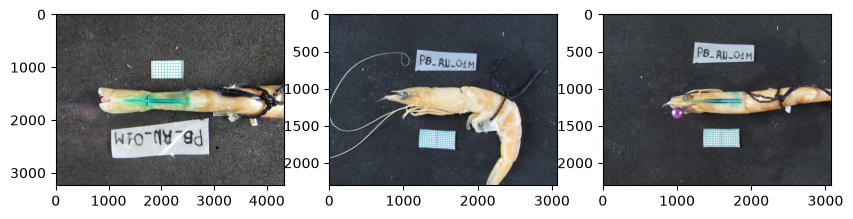

In [16]:
individuo = read_image_individuo(views_list_image_paths[0])

img_individuo = individuo.get_images()

plt.figure(figsize=(10,10))
plt.subplot(1,3,1)
plt.imshow(img_individuo["6_somito"])
plt.subplot(1,3,2)
plt.imshow(img_individuo["carapaca"])
plt.subplot(1,3,3)
plt.imshow(img_individuo["suco_adrostral"])


Observando canais da imagem em RGB

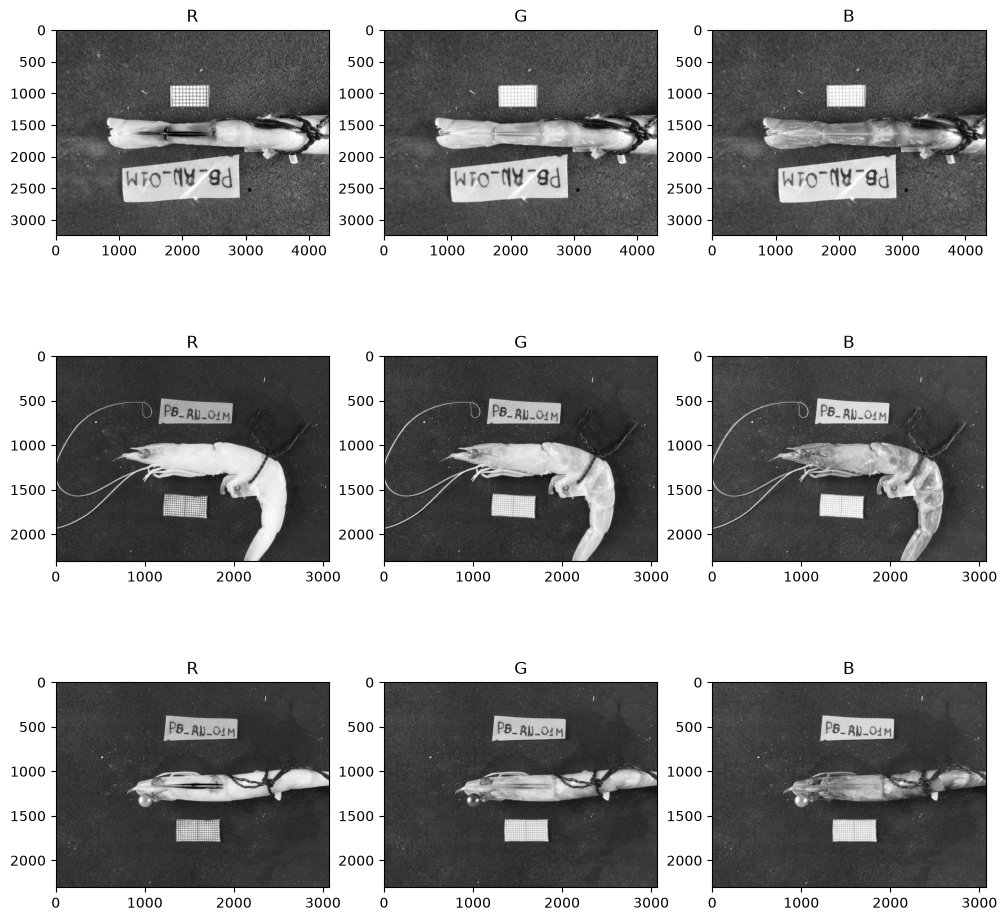

In [17]:
show_partes_individuo(img_individuo, "rgb")

Observando canais da imagem em HSV

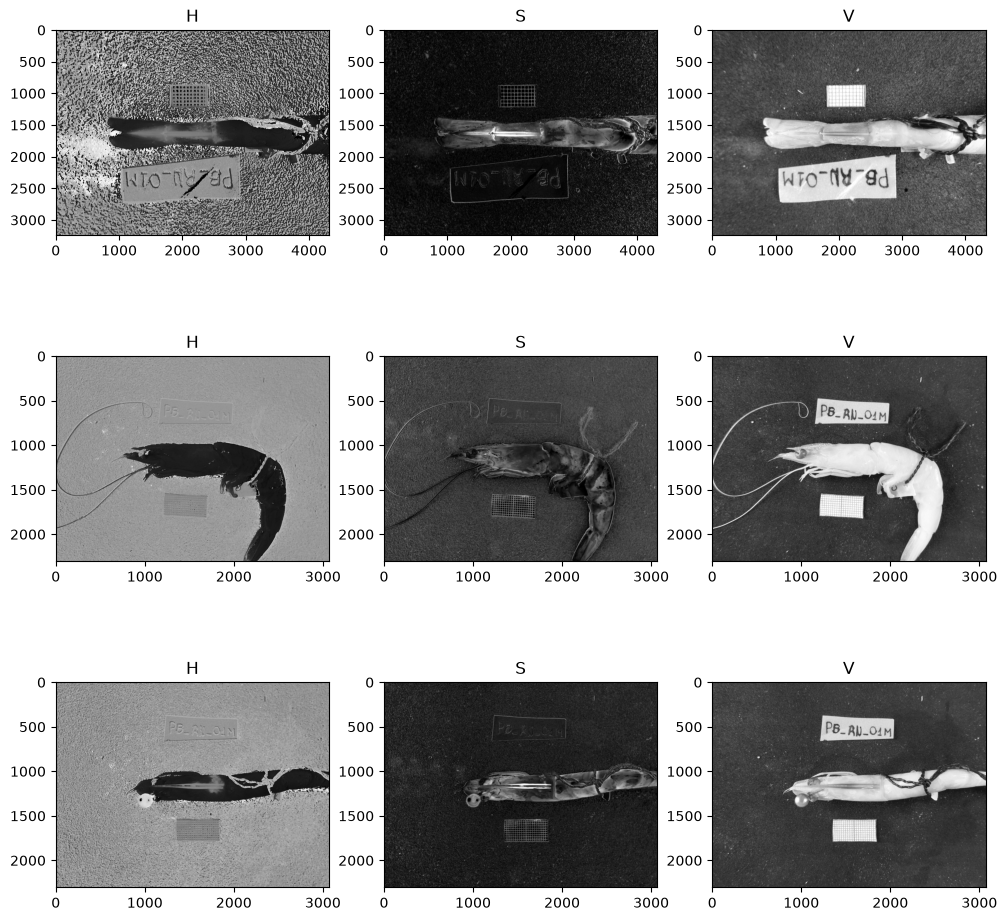

In [18]:
show_partes_individuo(img_individuo, "hsv")

In [19]:
def fill_holes(binary):
    h, w = binary.shape
    mask = np.zeros((h+2, w+2), np.uint8)

    flood = binary.copy()
    cv.floodFill(flood, mask, (0, 0), 255)

    flood_inv = cv.bitwise_not(flood)
    filled = binary | flood_inv

    return filled

Observando canais da imagem em LAB

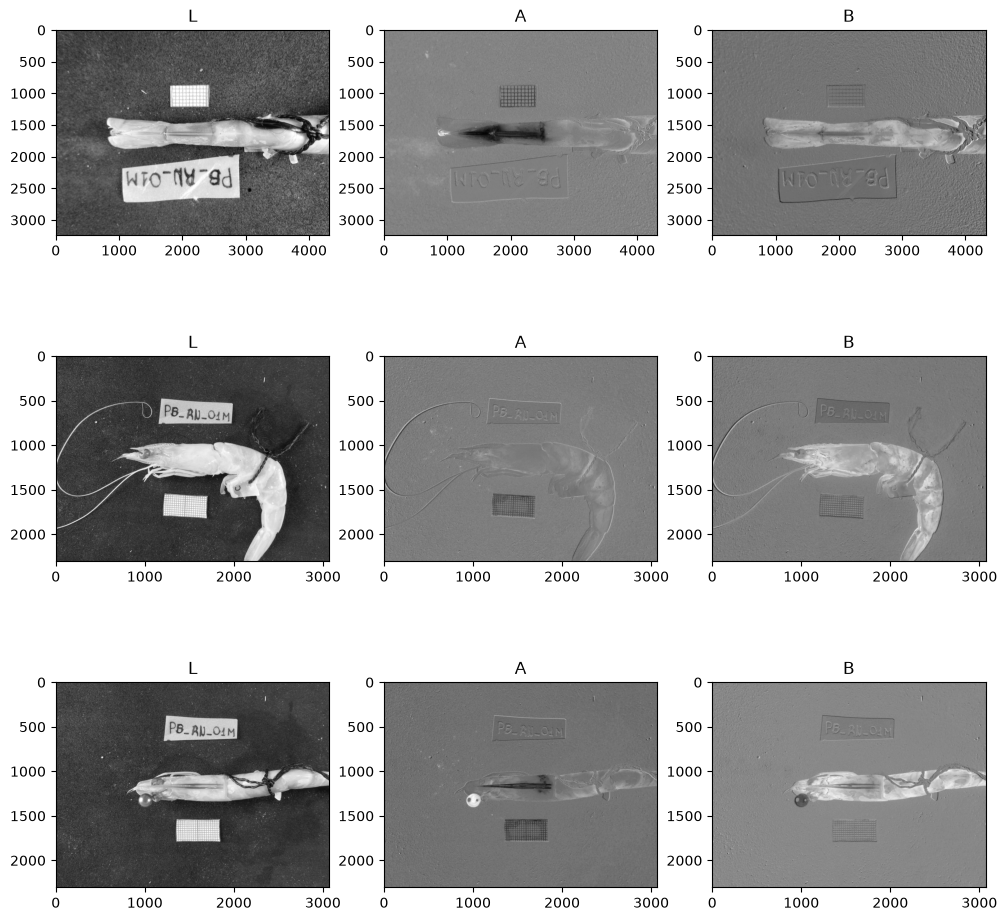

In [20]:
show_partes_individuo(img_individuo, "lab")

Observando canais da imagem em ycrcb

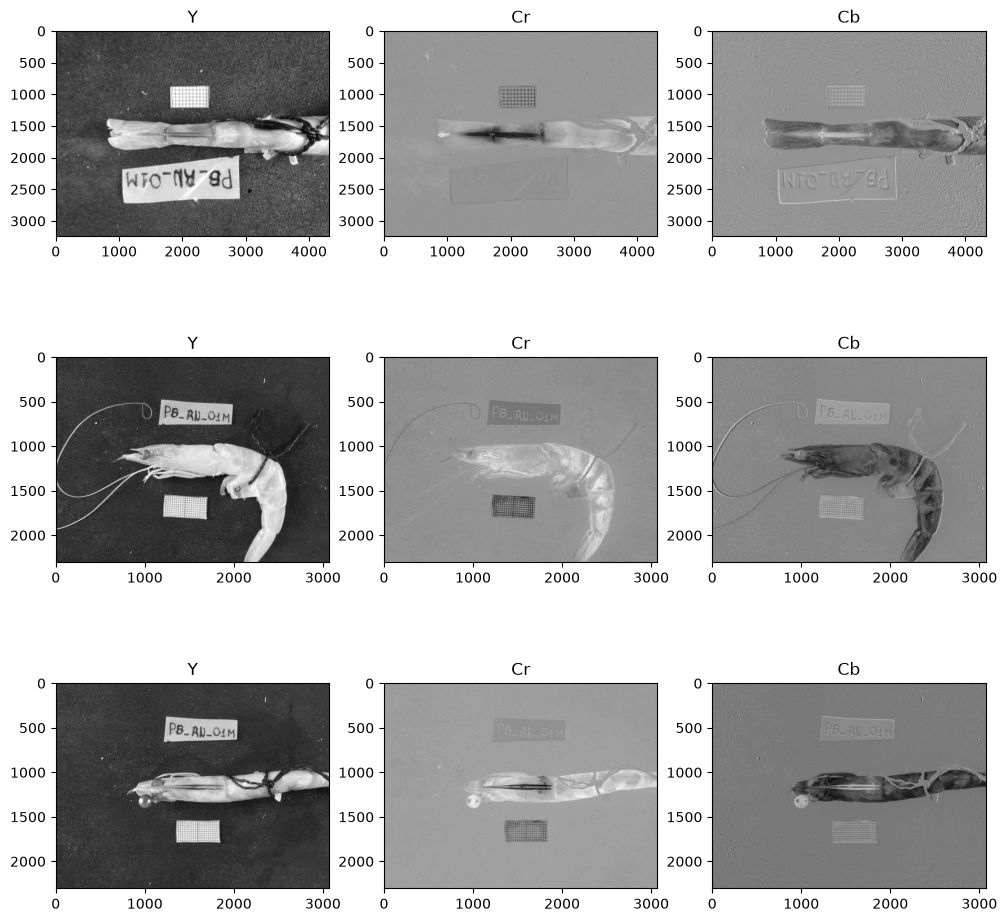

In [21]:
show_partes_individuo(img_individuo, "ycrcb")

Observando canais da imagem em CMYK

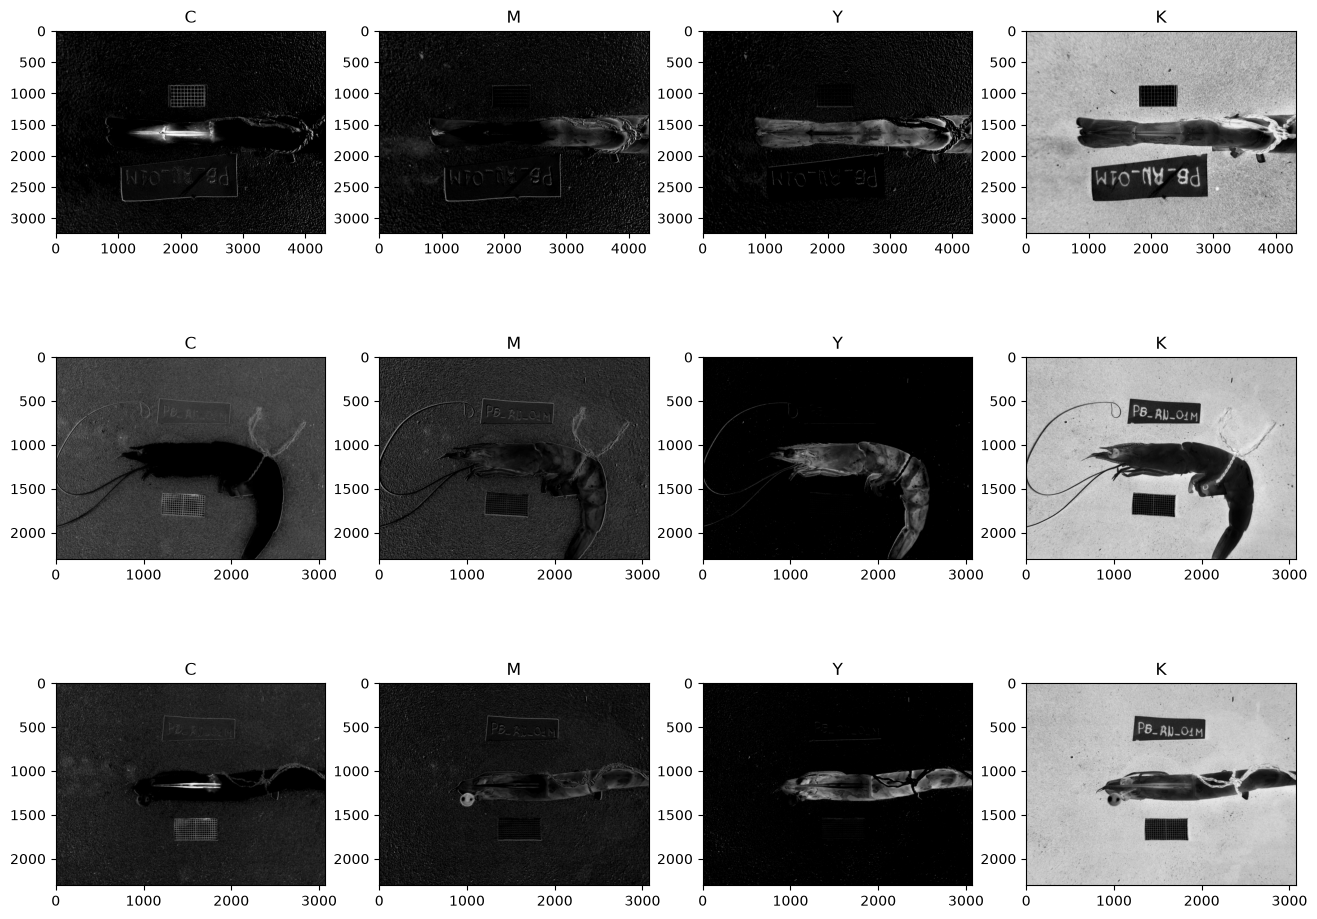

In [22]:
show_partes_individuo(img_individuo, "cmyk")

Segmentando carapaça utilizando canal HSV

In [23]:
def fill_holes(binary):
    h, w = binary.shape
    mask = np.zeros((h+2, w+2), np.uint8)

    flood = binary.copy()
    cv.floodFill(flood, mask, (0, 0), 255)

    flood_inv = cv.bitwise_not(flood)
    filled = binary | flood_inv

    return filled

In [24]:
def segmentation_carapaca(img):
    individuo_hsv = split_channels(img, "hsv")

    sub_h_v = cv.subtract(individuo_hsv["V"], individuo_hsv["H"])
    sum_h_v = cv.add(sub_h_v, individuo_hsv["H"])

    _,binary = cv.threshold(sum_h_v, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
    contours, _ = cv.findContours(binary, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)

    # pega o maior contorno
    largest = max(contours, key=cv.contourArea)

    # máscara vazia
    mask = np.zeros_like(individuo_hsv["V"])

    # desenha o maior objeto
    cv.drawContours(mask, [largest], -1, 255, -1)

    result = cv.bitwise_and(img, img, mask=mask)

    plt.figure(figsize=(10,10))
    plt.imshow(result, cmap="gray")



In [ ]:
def segmentation_suco_adrostral(img):
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    sam = sam_model_registry["vit_h"](
        checkpoint="../sams_models/sam_vit_h_4b8939.pth"
    )

    sam.to(device)
    predictor = SamPredictor(sam)

    predictor.set_image(img)

    h, w = img.shape[:2]

    input_point = np.array([[w // 2, h // 2]])
    input_label = np.array([1])

    masks, scores, logits = predictor.predict(
        point_coords=input_point,
        point_labels=input_label,
        multimask_output=True
    )

    mask = masks[len(masks)-1]
    mask = mask.astype(np.uint8) * 255

    result = cv.bitwise_and(img, img, mask=mask)
    return result
    # plt.figure(figsize=(18, 6))
    # plt.imshow(result)
    # plt.tight_layout()
    # plt.show()

segmentation_suco_adrostral(img_individuo["suco_adrostral"])


FileNotFoundError: [Errno 2] No such file or directory: './sams_models/sam_vit_h_4b8939.pth'

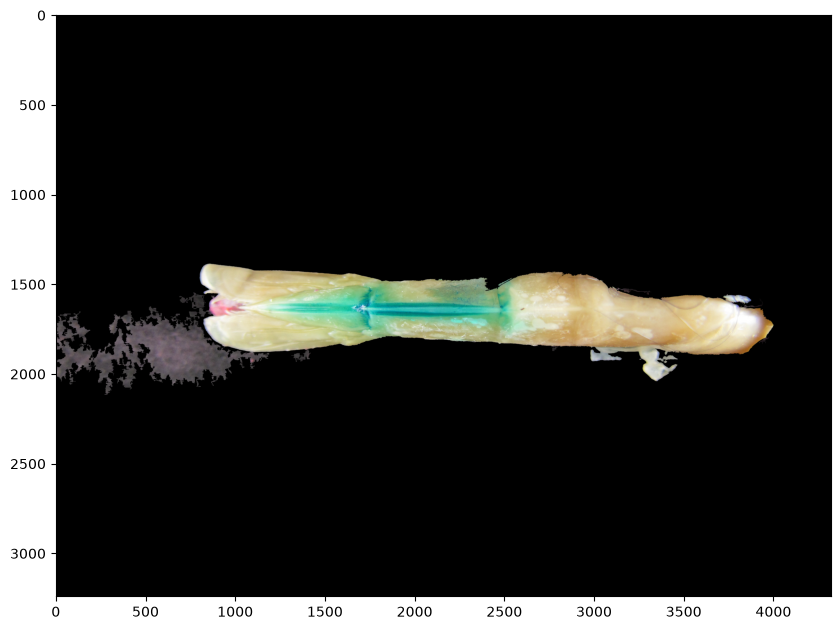

In [ ]:
def segmentation_6_somito(img):
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    sam = sam_model_registry["vit_h"](
        checkpoint="../sams_models/sam_vit_h_4b8939.pth"
    )

    sam.to(device)
    predictor = SamPredictor(sam)

    predictor.set_image(img)

    h, w = img.shape[:2]

    input_point = np.array([[w // 2, h // 2]])
    input_label = np.array([1])

    masks, scores, logits = predictor.predict(
        point_coords=input_point,
        point_labels=input_label,
        multimask_output=True
    )

    mask = masks[len(masks)-1]
    mask = mask.astype(np.uint8) * 255

    result = cv.bitwise_and(img, img, mask=mask)
    return result
    # plt.figure(figsize=(18, 6))
    # plt.imshow(result)
    # plt.tight_layout()
    # plt.show()

segmentation_carapaca(img_individuo["6_somito"])


In [ ]:
def segmentation_carapaca(img):
    
    device = "cuda" if torch.cuda.is_available() else "cpu"
    sam = sam_model_registry["vit_h"](
        checkpoint="../sams_models/sam_vit_h_4b8939.pth"
    )

    sam.to(device)
    predictor = SamPredictor(sam)

    predictor.set_image(img)

    h, w = img.shape[:2]

    input_point = np.array([[w // 2, h // 2]])
    input_label = np.array([1])

    masks, scores, logits = predictor.predict(
        point_coords=input_point,
        point_labels=input_label,
        multimask_output=True
    )

    mask = masks[len(masks)-1]
    mask = mask.astype(np.uint8) * 255

    result = cv.bitwise_and(img, img, mask=mask)
    return result
    # plt.figure(figsize=(18, 6))
    # plt.imshow(result)
    # plt.tight_layout()
    # plt.show()

segmentation_carapaca(img_individuo["carapaca"])


array([[[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]]], shape=(2304, 3072, 3), dtype=uint8)

Criação de Dataset de imagens segmentadas em tom de cores RGB

In [ ]:
os.makedirs("../dataset_segmentation_rgb", exist_ok=True)

for label in labels_paths:
    os.makedirs(f"../dataset_segmentation_rgb/{label}", exist_ok=True)

for index, individuo_path in enumerate(views_list_image_paths):
    individuo = read_image_individuo(individuo_path)
    print(f"{individuo.name}, {individuo.especie}")

    somito_6_segmentation = segmentation_6_somito(individuo.somito_6_image)
    carapaca_segmentation  = segmentation_carapaca(individuo.carapaca_image)
    suco_adrostral_segmentation = segmentation_suco_adrostral(individuo.suco_adrostral_image)

    os.makedirs(f"../dataset_segmentation_rgb/{individuo.especie}/{individuo.name}",exist_ok=True) 

    cv.imwrite(f"../dataset_segmentation_rgb/{individuo.especie}/{individuo.name}/{individuo.name}_6_somito.png", somito_6_segmentation)
    cv.imwrite(f"../dataset_segmentation_rgb/{individuo.especie}/{individuo.name}/{individuo.name}_suco_adostral.png", suco_adrostral_segmentation)
    cv.imwrite(f"../dataset_segmentation_rgb/{individuo.especie}/{individuo.name}/{individuo.name}_carapaca.png", carapaca_segmentation)

    

NameError: name 'labels_paths' is not defined

Criação de Dataset de imagens segmentadas em escala de cinza

In [ ]:
os.makedirs("../dataset_segmentation_cinza", exist_ok=True)

for label in labels_paths:
    os.makedirs(f"../dataset_segmentation_cinza/{label}", exist_ok=True)

for index, individuo_path in enumerate(views_list_image_paths):
    individuo = read_image_individuo(individuo_path)
    print(f"{individuo.name}, {individuo.especie}")

    somito_6_segmentation = segmentation_6_somito(individuo.somito_6_image)
    carapaca_segmentation  = segmentation_carapaca(individuo.carapaca_image)
    suco_adrostral_segmentation = segmentation_suco_adrostral(individuo.suco_adrostral_image)

    somito_6_segmentation_cinza = cv.cvtColor(somito_6_segmentation, cv.COLOR_BGR2GRAY)
    carapaca_segmentation_cinza = cv.cvtColor(carapaca_segmentation, cv.COLOR_BGR2GRAY)
    suco_adrostral_segmentation_cinza = cv.cvtColor(suco_adrostral_segmentation, cv.COLOR_BGR2GRAY)

    os.makedirs(f"../dataset_segmentation_cinza/{individuo.especie}/{individuo.name}",exist_ok=True) 

    cv.imwrite(f"../dataset_segmentation_cinza/{individuo.especie}/{individuo.name}/{individuo.name}_6_somito.png", somito_6_segmentation_cinza)
    cv.imwrite(f"../dataset_segmentation_cinza/{individuo.especie}/{individuo.name}/{individuo.name}_suco_adostral.png", carapaca_segmentation_cinza)
    cv.imwrite(f"../dataset_segmentation_cinza/{individuo.especie}/{individuo.name}/{individuo.name}_carapaca.png", suco_adrostral_segmentation_cinza)

    